# Analysis Question: What drives late deliveries most?
Exploratory data analysis of food delivery orders.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
print("Importing completed!")

Importing completed!


## 1. Load and clean the data

In [2]:
df = pd.read_csv('orders.csv')
df.head()

,OrderID,OrderValue,DistanceKm,Weather,TrafficLevel,VehicleType,PreparationTimeMin,DeliveryTimeMin,CustomerRating,LateDelivery
0,FD00001,524.44,2.15,Rainy,Medium,Scooter,20,53,3.7,Yes
1,FD00002,527.11,0.64,Clear,High,Scooter,27,51,4.1,Yes
2,FD00003,683.75,6.34,Clear,Medium,Bike,25,64,4.2,Yes
3,FD00004,472.08,3.24,Clear,Low,Car,29,50,3.4,Yes
4,FD00005,690.38,3.35,Clear,Medium,Bike,5,25,3.7,No


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1005 entries, 0 to 1004
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   OrderID             1005 non-null   str    
 1   OrderValue          993 non-null    float64
 2   DistanceKm          1005 non-null   float64
 3   Weather             995 non-null    str    
 4   TrafficLevel        1005 non-null   str    
 5   VehicleType         1005 non-null   str    
 6   PreparationTimeMin  1005 non-null   int64  
 7   DeliveryTimeMin     1005 non-null   int64  
 8   CustomerRating      990 non-null    float64
 9   LateDelivery        1005 non-null   str    
dtypes: float64(3), int64(2), str(5)
memory usage: 78.6 KB


In [4]:
print("Missing values (%):")
print((df.isnull().sum() / len(df) * 100).round(2))
print("\nDuplicate rows:", df.duplicated().sum())

Missing values (%):
OrderID               0.00
OrderValue            1.19
DistanceKm            0.00
Weather               1.00
TrafficLevel          0.00
VehicleType           0.00
PreparationTimeMin    0.00
DeliveryTimeMin       0.00
CustomerRating        1.49
LateDelivery          0.00
dtype: float64

Duplicate rows: 5


Missing values are under 1.5% in every column, so dropping those rows loses very little. Duplicates are removed first.

In [5]:
df = df.drop_duplicates()
df = df.dropna().reset_index(drop=True)

# Numeric target for rate calculations: 1 = late, 0 = on time
df['Late'] = (df['LateDelivery'] == 'Yes').astype(int)

print(f"Rows after cleaning: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

Rows after cleaning: 964
Columns: 11


In [6]:
df.describe().round(2)

,OrderValue,DistanceKm,PreparationTimeMin,DeliveryTimeMin,CustomerRating,Late
count,964.00,964.00,964.00,964.00,964.00,964.00
mean,428.30,4.76,17.99,53.53,4.07,0.70
std,170.14,3.17,6.11,14.10,0.66,0.46
min,80.00,0.40,5.00,17.00,1.30,0.00
25%,312.16,2.41,13.00,43.00,3.60,0.00
50%,420.56,4.10,18.00,53.00,4.10,1.00
75%,544.84,6.36,22.00,62.00,4.60,1.00
max,953.75,18.00,39.00,100.00,5.00,1.00


## 2. Overall late rate

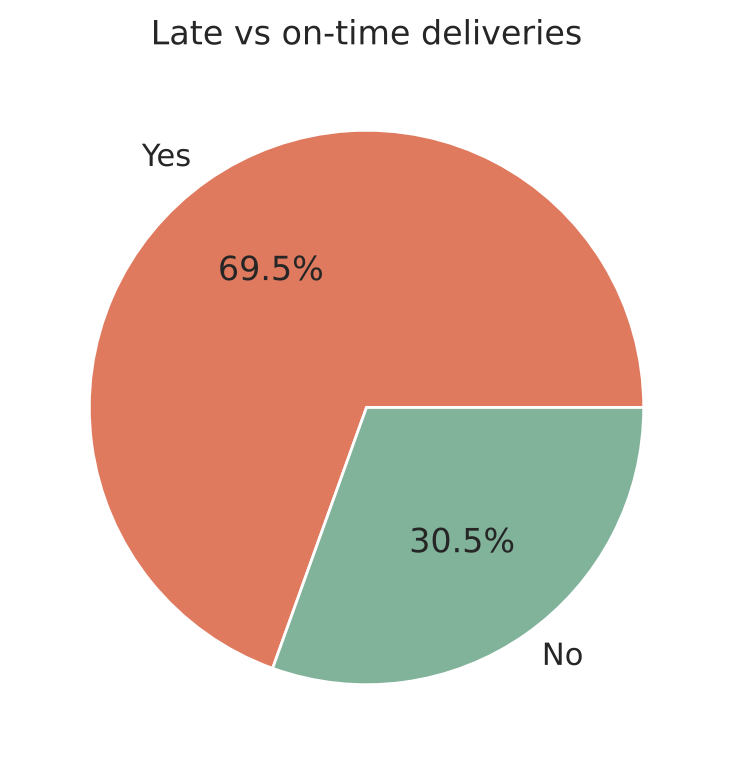

In [7]:
counts = df['LateDelivery'].value_counts()
plt.figure(figsize=(4.5, 4.5))
plt.pie(counts, labels=counts.index, autopct="%1.1f%%", colors=["#e07a5f", "#81b29a"] if counts.index[0]=="Yes" else ["#81b29a", "#e07a5f"])
plt.title("Late vs on-time deliveries")
plt.show()

**Roughly 7 in 10 orders arrive late**, so lateness is the norm here, not the exception.

## 3. Check for leakage in `DeliveryTimeMin`

In [8]:
df.groupby('LateDelivery')['DeliveryTimeMin'].agg(['min', 'max'])

,min,max
LateDelivery,,
No,17,45
Yes,46,100


The ranges do not overlap: every order over 45 minutes is late and every order at or under 45 is on time. So **`DeliveryTimeMin` is how “late” is defined, not a cause of it**. `CustomerRating` is recorded after delivery, so it is an outcome as well. Both are excluded from the driver analysis below. Prep time, distance, traffic, weather, vehicle and order value are the real candidates.

## 4. Numeric features vs late delivery

In [9]:
driver_num = ["DistanceKm", "PreparationTimeMin", "OrderValue"]
df.groupby("LateDelivery")[driver_num].mean().round(2)

,DistanceKm,PreparationTimeMin,OrderValue
LateDelivery,,,
No,2.64,14.05,438.1
Yes,5.70,19.71,424.0


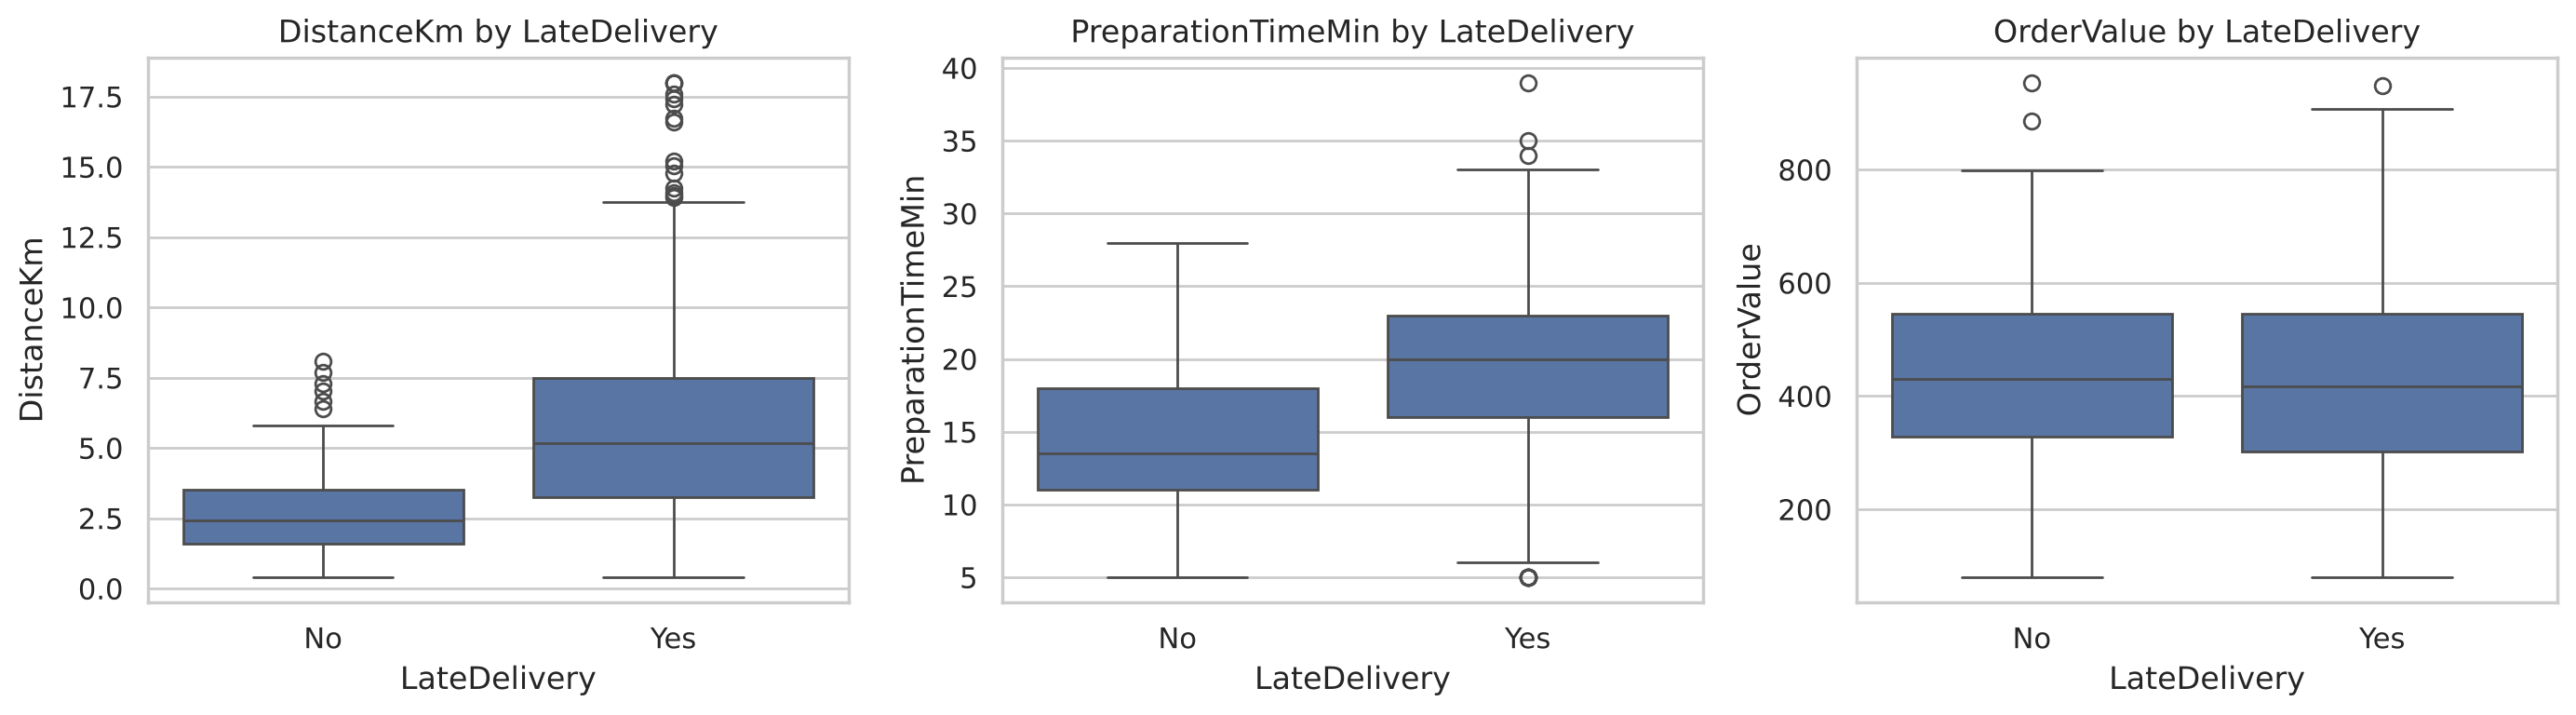

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, driver_num):
    sns.boxplot(data=df, x="LateDelivery", y=col, order=["No", "Yes"], ax=ax)
    ax.set_title(col + " by LateDelivery")
plt.tight_layout()
plt.show()

Late orders travel about twice as far and take longer to prepare. Order value looks almost identical in both groups.

### Late rate by distance and prep-time band
Binning shows how the late rate changes as each factor grows.

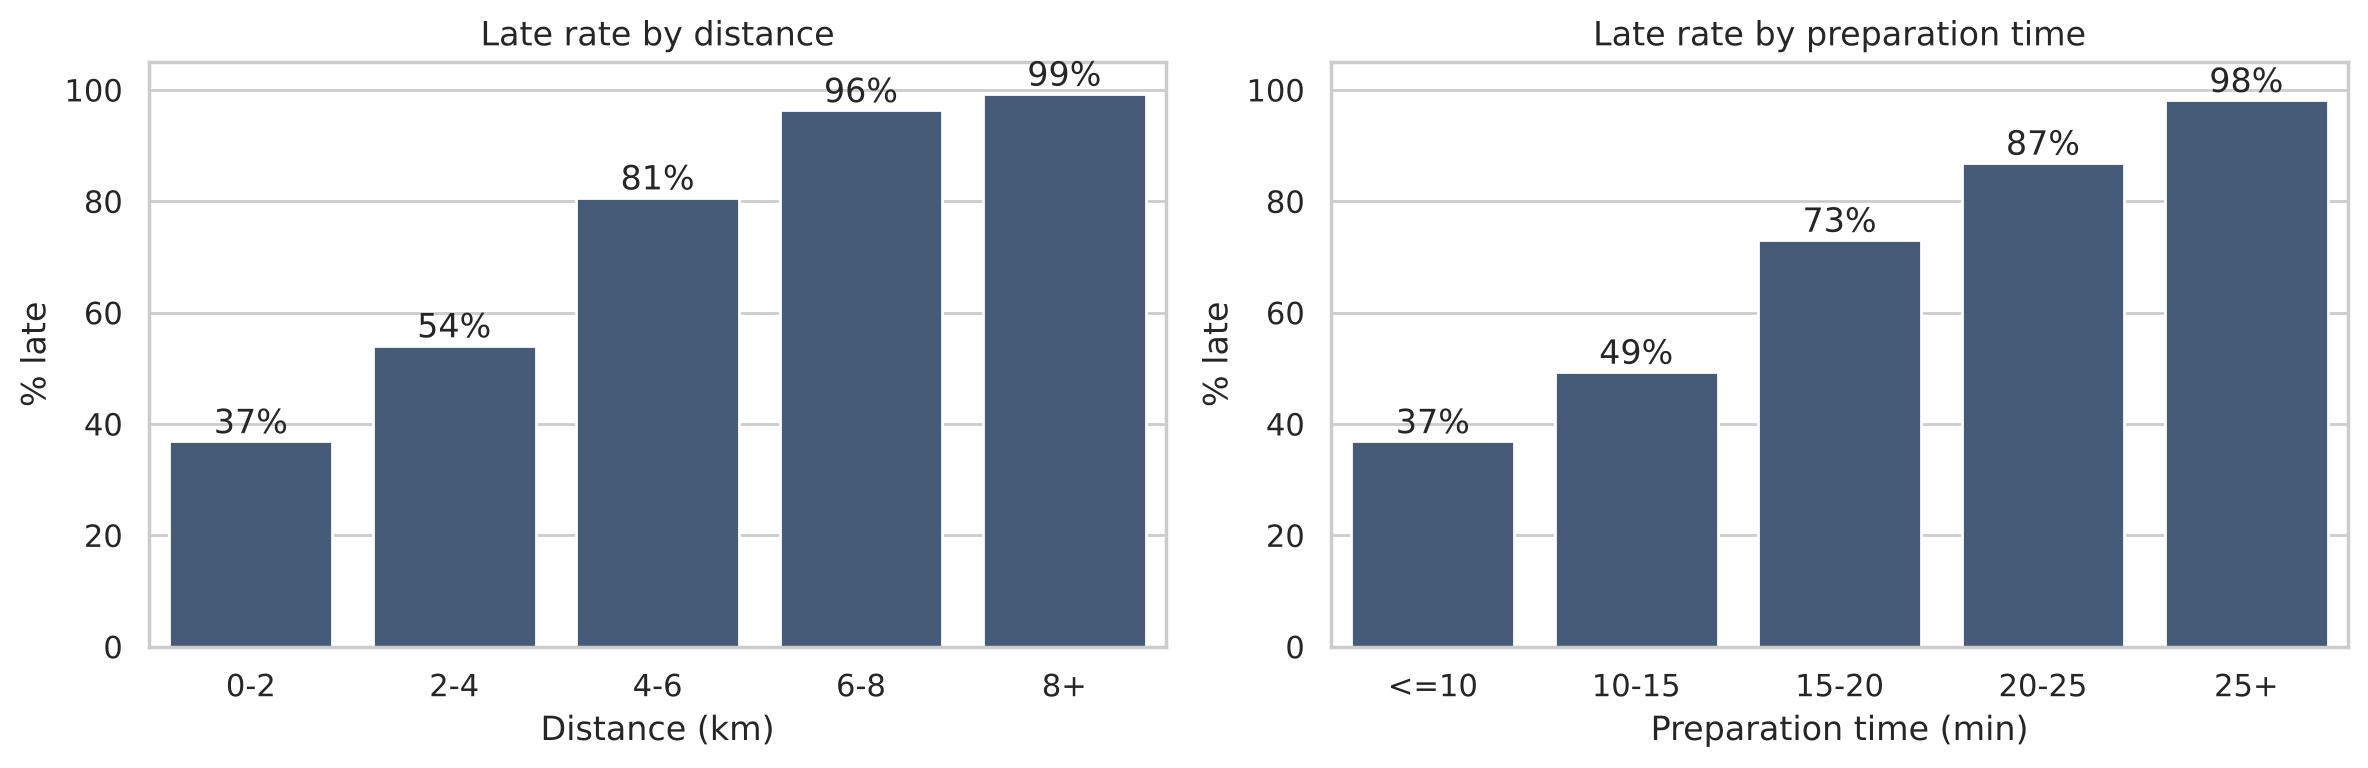

In [11]:
df['DistanceBand'] = pd.cut(df['DistanceKm'], [0, 2, 4, 6, 8, 20],
                            labels=["0-2", "2-4", "4-6", "6-8", "8+"])
df['PrepBand'] = pd.cut(df['PreparationTimeMin'], [0, 10, 15, 20, 25, 40],
                        labels=["<=10", "10-15", "15-20", "20-25", "25+"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, xlabel in zip(axes, ["DistanceBand", "PrepBand"], ["Distance (km)", "Preparation time (min)"]):
    rate = df.groupby(col, observed=True)['Late'].mean() * 100
    sns.barplot(x=rate.index, y=rate.values, ax=ax, color="#3d5a80")
    ax.set_xlabel(xlabel); ax.set_ylabel("% late"); ax.set_ylim(0, 105)
    ax.set_title(f"Late rate by {xlabel.split(' (')[0].lower()}")
    for i, v in enumerate(rate.values):
        ax.text(i, v + 1.5, f"{v:.0f}%", ha="center")
plt.tight_layout()
plt.show()

Both factors have a steep, consistent effect. Beyond about 6 km, almost every order is late. Prep time over 25 minutes is also nearly always late.

## 5. Categorical features vs late delivery
These plots use the **late rate per category** instead of raw counts, so groups with more orders don't look worse just because they're bigger.

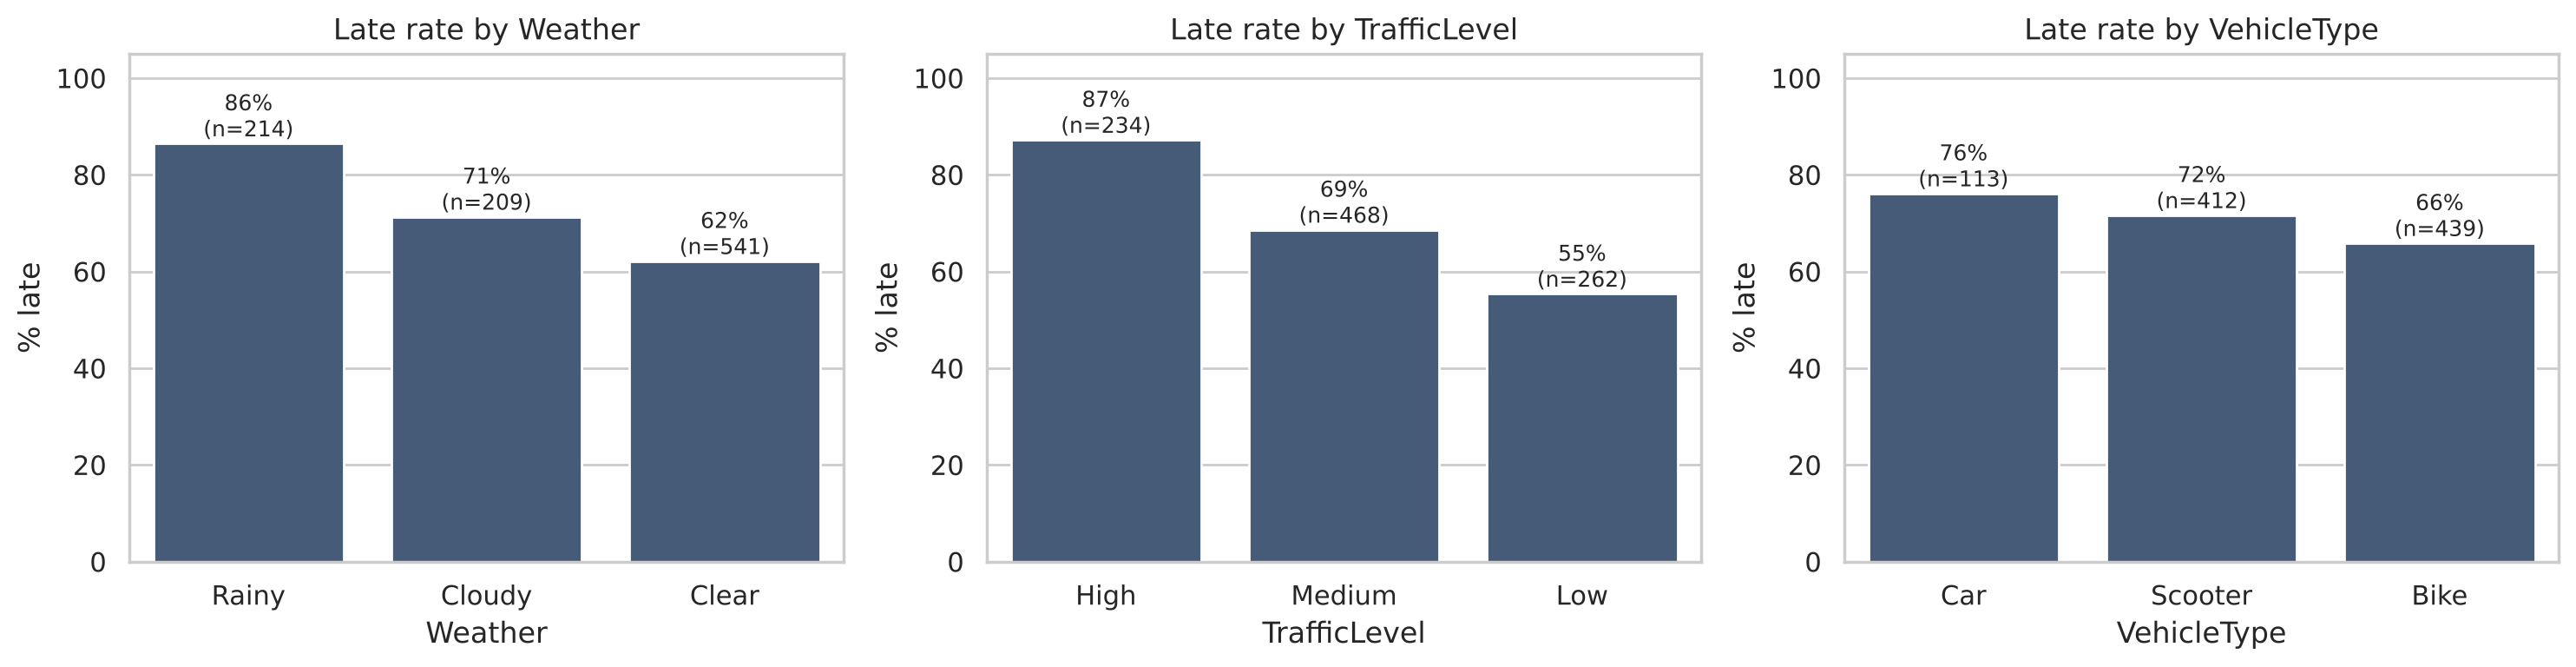

In [12]:
cat_cols = ["Weather", "TrafficLevel", "VehicleType"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, cat_cols):
    g = df.groupby(col)['Late'].agg(['mean', 'count']).sort_values('mean', ascending=False)
    sns.barplot(x=g.index, y=g['mean'] * 100, ax=ax, color="#3d5a80")
    ax.set_ylabel("% late"); ax.set_ylim(0, 105); ax.set_title(f"Late rate by {col}")
    for i, (m, n) in enumerate(zip(g['mean'], g['count'])):
        ax.text(i, m * 100 + 1.5, f"{m*100:.0f}%\n(n={n})", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

Traffic and weather both matter: high traffic and rain push the late rate well above average. Vehicle type has a smaller effect, and cars have the fewest orders, so that comparison is less reliable.

## 6. Ranking the drivers side by side

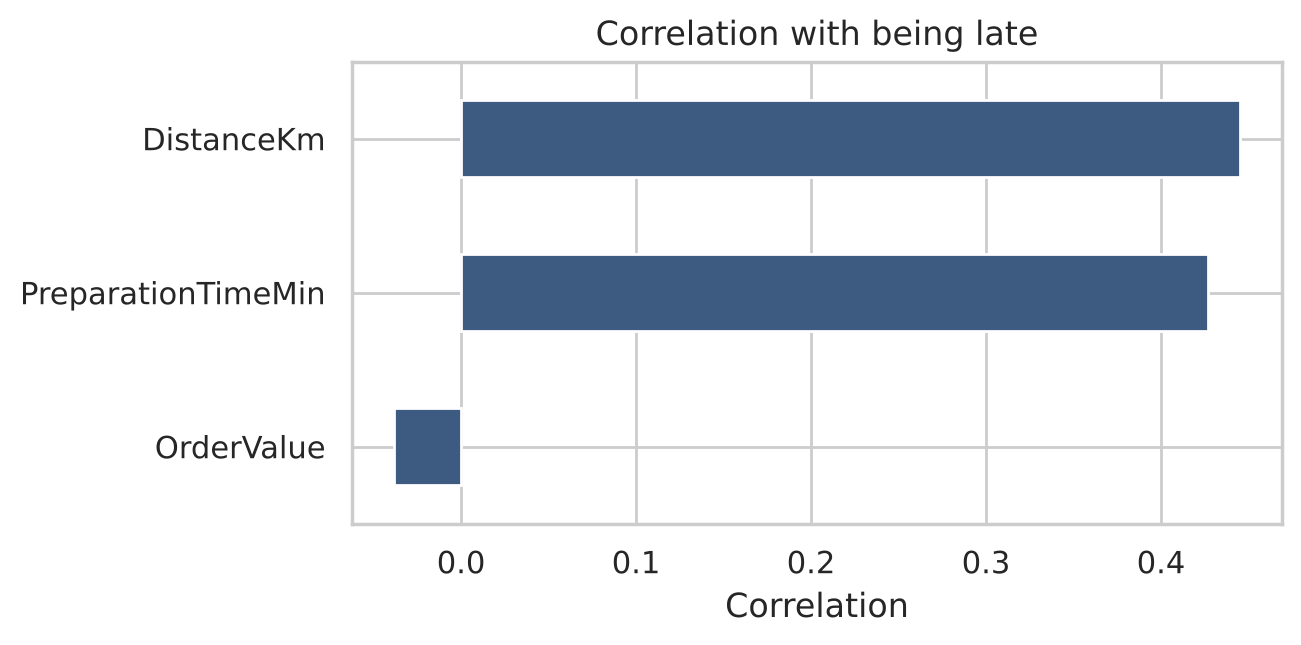

In [13]:
corr = df[["DistanceKm", "PreparationTimeMin", "OrderValue", "Late"]].corr()['Late'].drop('Late')
corr.sort_values().plot.barh(color="#3d5a80", figsize=(6, 3))
plt.title("Correlation with being late")
plt.xlabel("Correlation")
plt.show()

In [14]:
# Spread in late rate between best and worst category of each categorical factor
spread = {col: (df.groupby(col)['Late'].mean().max() - df.groupby(col)['Late'].mean().min()) * 100
          for col in cat_cols}
pd.Series(spread, name="Late-rate gap (percentage points)").sort_values(ascending=False).round(1)

TrafficLevel    31.8
Weather         24.3
VehicleType     10.3
Name: Late-rate gap (percentage points), dtype: float64

## 7. Findings

**Distance is the strongest driver.** The late rate goes from about 39% under 2 km to over 96% beyond 6 km.

**Preparation time is a close second.** It goes from about 38% at 10 minutes or less to about 97% above 25 minutes.

**Traffic and weather add to the problem.** High traffic is late about 88% of the time versus 55% for low traffic. Rain is about 87% versus 62% in clear weather.

**Vehicle type and order value matter little.** Order value has almost no relationship with lateness.

**Caveat:** this shows association, not proof of cause. Distance and prep time may also interact with traffic, which is worth a closer look.